In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from ase.io import iread

root = Path(
    r"\\wsl.localhost\Ubuntu-22.04\home\james\mphil-amm-practical2"
)

ff_dir = root / "01-FF-Water"
mlp_dir = root / "02-MLP-Water"

ff_energy = ff_dir / "H2O-64-FF-1.ener"
mlp_energy = mlp_dir / "H2O-64-NNP-1.ener"

print("FF:", ff_energy.exists())
print("MLP:", mlp_energy.exists())

FF: True
MLP: True


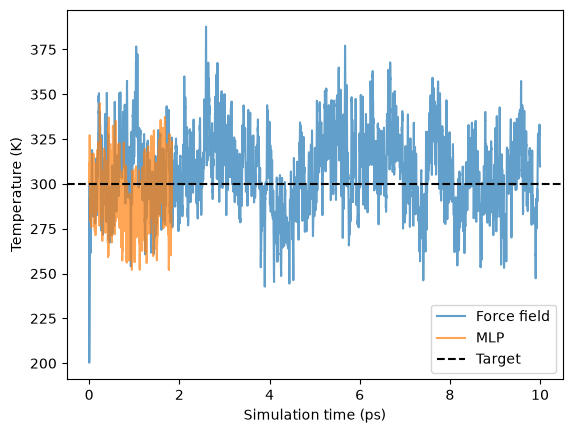

In [2]:
ff = np.loadtxt(ff_energy, comments="#")
mlp = np.loadtxt(mlp_energy, comments="#")

plt.plot(ff[:, 1] / 1000, ff[:, 3], label="Force field", alpha=0.7)
plt.plot(mlp[:, 1] / 1000, mlp[:, 3], label="MLP", alpha=0.7)

plt.axhline(300, color="black", linestyle="--", label="Target")

plt.xlabel("Simulation time (ps)")
plt.ylabel("Temperature (K)")
plt.legend()
plt.show()

Force field:
  Total change: -0.084491 Ha
  Drift rate:    -0.000002 Ha/ps

MLP:
  Total change: 0.000233 Ha
  Drift rate:    0.000065 Ha/ps



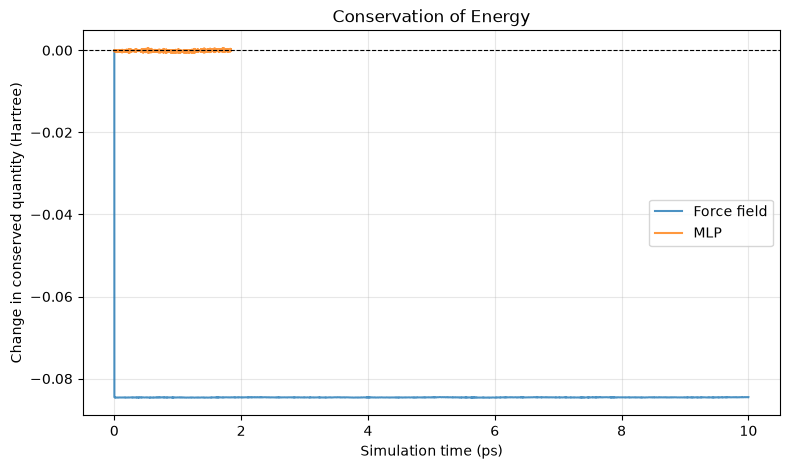

In [3]:
import numpy as np
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9, 5))

for data, label in [(ff, "Force field"), (mlp, "MLP")]:

    time = data[:, 1] / 1000  # fs → ps
    conserved = data[:, 5]    # Hartree

    # Change relative to the initial conserved quantity
    delta_E = conserved - conserved[0]

    ax.plot(time, delta_E, label=label, alpha=0.8)

    # Linear fit to quantify systematic energy drift
    slope, intercept = np.polyfit(time, delta_E, 1)

    print(f"{label}:")
    print(f"  Total change: {delta_E[-1]:.6f} Ha")
    print(f"  Drift rate:    {slope:.6f} Ha/ps")
    print()

ax.axhline(0, color="black", linestyle="--", linewidth=0.8)
ax.set_xlabel("Simulation time (ps)")
ax.set_ylabel("Change in conserved quantity (Hartree)")
ax.set_title("Conservation of Energy")
ax.legend()
ax.grid(alpha=0.3)

plt.show()


Force field:
Step     Time (fs)     Conserved quantity (Ha)
   0         0.000     -0.89707825
   1         1.000     -0.98160161
   2         2.000     -0.98159824
   3         3.000     -0.98160080
   4         4.000     -0.98160837

MLP:
Step     Time (fs)     Conserved quantity (Ha)
   0         0.000     3751.52256949
   1         0.500     3751.52240209
   2         1.000     3751.52232342
   3         1.500     3751.52236154
   4         2.000     3751.52243674
Force field drift: 4.451636e-06 Ha/ps
MLP drift: 6.549370e-05 Ha/ps


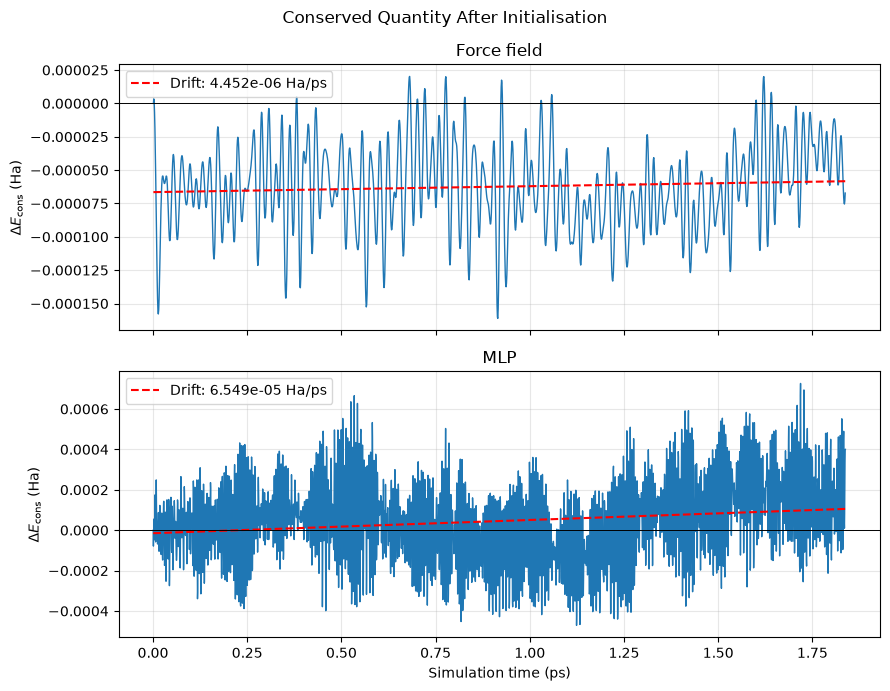

In [4]:
import numpy as np
import matplotlib.pyplot as plt

# Inspect the first five recorded values
for data, name in [(ff, "Force field"), (mlp, "MLP")]:
    print(f"\n{name}:")
    print("Step     Time (fs)     Conserved quantity (Ha)")
    for row in data[:5]:
        print(f"{int(row[0]):4d}     {row[1]:9.3f}     {row[5]:.8f}")

# Restrict comparison to the shorter simulation's duration
t_max = min(ff[-1, 1], mlp[-1, 1]) / 1000

fig, axes = plt.subplots(2, 1, figsize=(9, 7), sharex=True)

for ax, (data, name) in zip(
    axes, [(ff, "Force field"), (mlp, "MLP")]
):
    time = data[:, 1] / 1000

    # Exclude initial recorded step
    time = time[1:]
    energy = data[1:, 5]

    mask = time <= t_max
    time = time[mask]
    energy = energy[mask]

    # Re-reference energy after initialisation
    delta_E = energy - energy[0]

    slope, intercept = np.polyfit(time, delta_E, 1)

    ax.plot(time, delta_E, linewidth=1)
    ax.plot(
        time,
        slope * time + intercept,
        "r--",
        label=f"Drift: {slope:.3e} Ha/ps"
    )

    ax.axhline(0, color="black", linewidth=0.7)
    ax.set_ylabel(r"$\Delta E_{\mathrm{cons}}$ (Ha)")
    ax.set_title(name)
    ax.legend()
    ax.grid(alpha=0.3)

    print(f"{name} drift: {slope:.6e} Ha/ps")

axes[-1].set_xlabel("Simulation time (ps)")
fig.suptitle("Conserved Quantity After Initialisation")
plt.tight_layout()
plt.show()


Force field
Mean O-H length: 0.9999 Å
O-H std dev:     0.0016 Å
Mean H-O-H angle: 109.46°
Angle std dev:    0.29°

MLP
Mean O-H length: 0.9710 Å
O-H std dev:     0.0245 Å
Mean H-O-H angle: 105.46°
Angle std dev:    4.81°


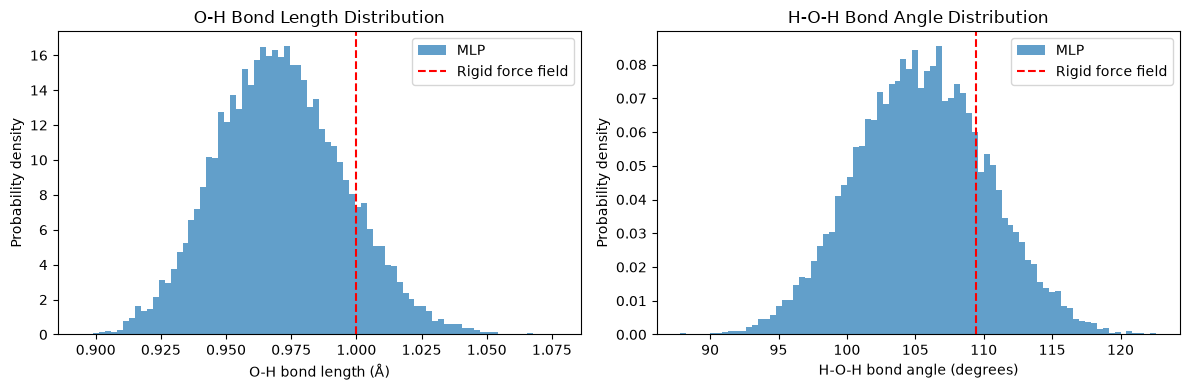

In [5]:
from ase.io import iread
import numpy as np
import matplotlib.pyplot as plt

# Simulation box length in Angstroms
L = 12.42

ff_xyz = ff_dir / "H2O-64-FF-pos-1.xyz"
mlp_xyz = mlp_dir / "H2O-64-NNP-pos-1.xyz"


def calculate_geometry(filepath, stride=20):
    """
    Calculate O-H bond lengths and H-O-H angles
    for all water molecules across sampled frames.
    """

    bond_lengths = []
    bond_angles = []

    for atoms in iread(str(filepath), index=f"::{stride}"):

        # Each water molecule is ordered O, H, H
        positions = atoms.get_positions().reshape(-1, 3, 3)

        oxygen = positions[:, 0, :]
        hydrogen1 = positions[:, 1, :]
        hydrogen2 = positions[:, 2, :]

        # O-H displacement vectors
        v1 = hydrogen1 - oxygen
        v2 = hydrogen2 - oxygen

        # Minimum-image periodic boundary conditions
        v1 -= L * np.rint(v1 / L)
        v2 -= L * np.rint(v2 / L)

        # Bond lengths
        r1 = np.linalg.norm(v1, axis=1)
        r2 = np.linalg.norm(v2, axis=1)

        bond_lengths.extend(r1)
        bond_lengths.extend(r2)

        # Bond angles via the dot product
        cos_theta = np.sum(v1 * v2, axis=1) / (r1 * r2)
        cos_theta = np.clip(cos_theta, -1, 1)

        theta = np.degrees(np.arccos(cos_theta))
        bond_angles.extend(theta)

    return np.array(bond_lengths), np.array(bond_angles)


# Calculate geometry for each model
ff_bonds, ff_angles = calculate_geometry(ff_xyz)
mlp_bonds, mlp_angles = calculate_geometry(mlp_xyz)

# Numerical summary
for name, bonds, angles in [
    ("Force field", ff_bonds, ff_angles),
    ("MLP", mlp_bonds, mlp_angles)
]:
    print(f"\n{name}")
    print(f"Mean O-H length: {np.mean(bonds):.4f} Å")
    print(f"O-H std dev:     {np.std(bonds):.4f} Å")
    print(f"Mean H-O-H angle: {np.mean(angles):.2f}°")
    print(f"Angle std dev:    {np.std(angles):.2f}°")


# Plot distributions
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(
    mlp_bonds, bins=80, density=True,
    alpha=0.7, label="MLP"
)
axes[0].axvline(
    np.mean(ff_bonds),
    color="red", linestyle="--",
    label="Rigid force field"
)
axes[0].set_xlabel("O-H bond length (Å)")
axes[0].set_ylabel("Probability density")
axes[0].set_title("O-H Bond Length Distribution")
axes[0].legend()

axes[1].hist(
    mlp_angles, bins=80, density=True,
    alpha=0.7, label="MLP"
)
axes[1].axvline(
    np.mean(ff_angles),
    color="red", linestyle="--",
    label="Rigid force field"
)
axes[1].set_xlabel("H-O-H bond angle (degrees)")
axes[1].set_ylabel("Probability density")
axes[1].set_title("H-O-H Bond Angle Distribution")
axes[1].legend()

plt.tight_layout()
plt.show()

Analysed times: 0.20 to 1.84 ps
Force-field frames: 164
MLP frames: 164


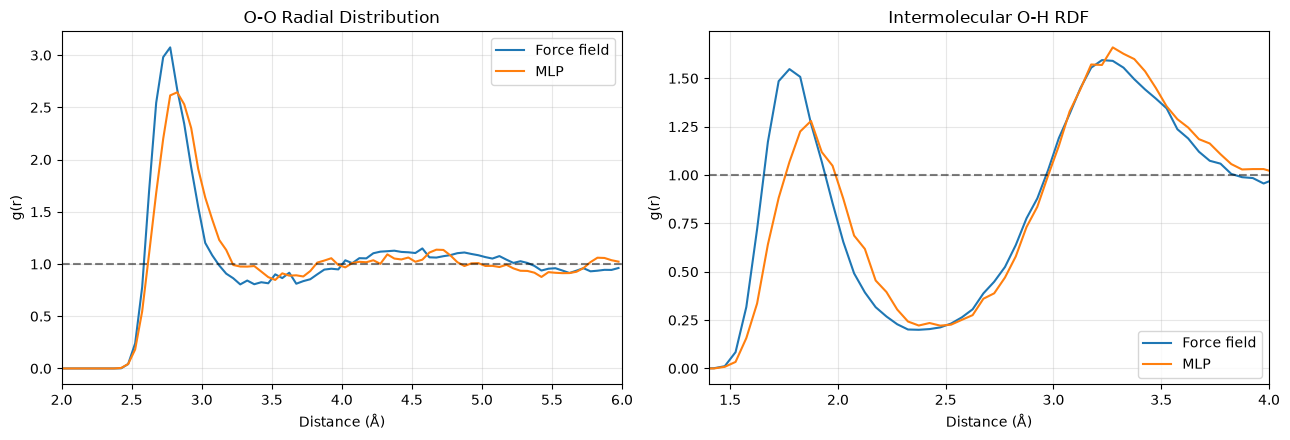

Force field: O-O peak at 2.775 Å, g = 3.07
MLP: O-O peak at 2.825 Å, g = 2.64


In [6]:

import numpy as np
import matplotlib.pyplot as plt
from ase.io import iread

# Cubic simulation box, Angstroms
L = 12.42
V = L**3

# RDF bins
dr = 0.05
edges = np.arange(0, 6.0 + dr / 2, dr)
r = (edges[1:] + edges[:-1]) / 2

# Exact volumes of spherical shells
shell_volumes = (4 * np.pi / 3) * (
    edges[1:]**3 - edges[:-1]**3
)

# Compare the same physical time interval in both simulations
end_ps = min(ff[-1, 1], mlp[-1, 1]) / 1000
equilibration_ps = 0.2  # Preliminary exclusion; not verified equilibrium


def calculate_rdf(filepath, energy_data):
    dt_fs = np.median(np.diff(energy_data[:, 1]))

    # Sample every approximately 10 fs
    start = int(np.ceil(equilibration_ps * 1000 / dt_fs))
    stop = int(np.floor(end_ps * 1000 / dt_fs)) + 1
    stride = max(1, int(round(10 / dt_fs)))

    oo_counts = np.zeros(len(r))
    oh_counts = np.zeros(len(r))
    nframes = 0

    # Unique O-O pairs
    oo_indices = np.triu_indices(64, k=1)

    # Exclude O-H pairs belonging to the same molecule
    oh_mask = np.ones((64, 128), dtype=bool)
    molecule_index = np.arange(64)
    oh_mask[molecule_index, 2 * molecule_index] = False
    oh_mask[molecule_index, 2 * molecule_index + 1] = False

    for atoms in iread(
        str(filepath),
        index=f"{start}:{stop}:{stride}"
    ):
        symbols = atoms.get_chemical_symbols()
        assert len(symbols) == 192
        assert symbols == ["O", "H", "H"] * 64

        positions = atoms.get_positions().reshape(64, 3, 3)

        oxygen = positions[:, 0, :]
        hydrogen = positions[:, 1:, :].reshape(128, 3)

        # Oxygen-oxygen distances
        d_oo = oxygen[:, None, :] - oxygen[None, :, :]
        d_oo -= L * np.rint(d_oo / L)

        distances_oo = np.linalg.norm(
            d_oo[oo_indices], axis=1
        )
        oo_counts += np.histogram(
            distances_oo, bins=edges
        )[0]

        # Oxygen-hydrogen distances (intermolecular only)
        d_oh = oxygen[:, None, :] - hydrogen[None, :, :]
        d_oh -= L * np.rint(d_oh / L)

        distances_oh = np.linalg.norm(d_oh, axis=2)
        oh_counts += np.histogram(
            distances_oh[oh_mask], bins=edges
        )[0]

        nframes += 1

    if nframes == 0:
        raise ValueError("No trajectory frames found in selected interval")

    # Normalise using expected pair counts for a uniform fluid
    n_pairs_oo = 64 * 63 / 2
    n_pairs_oh = 64 * 126

    g_oo = oo_counts / (
        nframes * n_pairs_oo * shell_volumes / V
    )
    g_oh = oh_counts / (
        nframes * n_pairs_oh * shell_volumes / V
    )

    return g_oo, g_oh, nframes


ff_oo, ff_oh, n_ff = calculate_rdf(ff_xyz, ff)
mlp_oo, mlp_oh, n_mlp = calculate_rdf(mlp_xyz, mlp)

print(f"Analysed times: {equilibration_ps:.2f} to {end_ps:.2f} ps")
print(f"Force-field frames: {n_ff}")
print(f"MLP frames: {n_mlp}")

# Plot the results
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

for ax, ff_g, mlp_g, title in [
    (axes[0], ff_oo, mlp_oo, "O-O Radial Distribution"),
    (axes[1], ff_oh, mlp_oh, "Intermolecular O-H RDF")
]:
    ax.plot(r, ff_g, label="Force field")
    ax.plot(r, mlp_g, label="MLP")
    ax.axhline(1, color="black", linestyle="--", alpha=0.5)

    ax.set_title(title)
    ax.set_xlabel("Distance (Å)")
    ax.set_ylabel("g(r)")
    ax.legend()
    ax.grid(alpha=0.3)

axes[0].set_xlim(2.0, 6.0)
axes[1].set_xlim(1.4, 4.0)

plt.tight_layout()
plt.show()

# Find the first O-O RDF peaks
for label, g in [("Force field", ff_oo), ("MLP", mlp_oo)]:
    mask = (r >= 2.3) & (r <= 3.4)
    peak_index = np.argmax(g[mask])

    peak_r = r[mask][peak_index]
    peak_height = g[mask][peak_index]

    print(f"{label}: O-O peak at {peak_r:.3f} Å, g = {peak_height:.2f}")


Force field
MSD slope: 1.8676 Å²/ps
Apparent D: 3.113e-09 m²/s

MLP
MSD slope: 0.9898 Å²/ps
Apparent D: 1.650e-09 m²/s



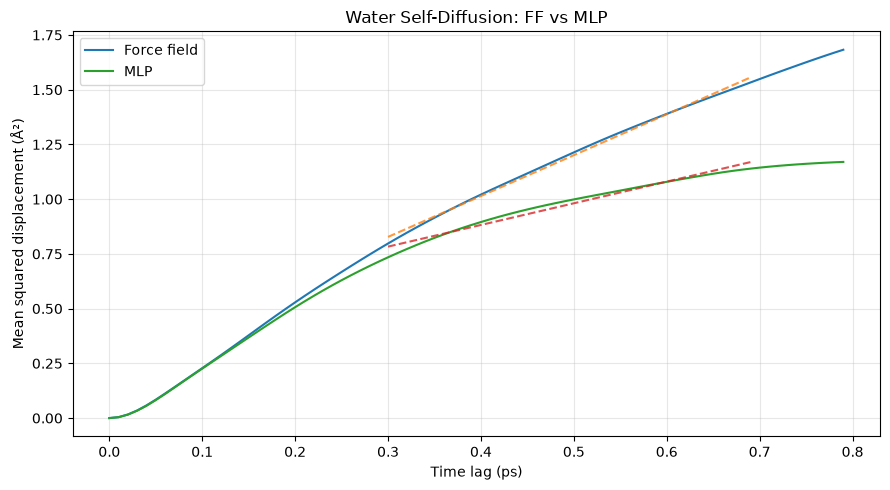

In [7]:

import numpy as np
import matplotlib.pyplot as plt
from ase.io import iread

L = 12.42
equilibration_ps = 0.2
end_ps = min(ff[-1, 1], mlp[-1, 1]) / 1000


def load_oxygen_positions(filepath, energy_data):
    """Load oxygen trajectories and reconstruct continuous positions."""

    dt_fs = np.median(np.diff(energy_data[:, 1]))
    stride = max(1, round(10 / dt_fs))
    n_target = int(np.floor(end_ps * 1000 / dt_fs)) + 1

    positions = []
    previous = None
    unwrapped = None
    n_read = 0

    # Assumes the original CP2K trajectory saves every MD step.
    for i, atoms in enumerate(iread(str(filepath),
                                    index=f":{n_target}")):
        current = atoms.get_positions()[::3]

        if previous is None:
            unwrapped = current.copy()
        else:
            displacement = current - previous

            # Correct boundary crossings if positions are wrapped
            displacement -= L * np.rint(displacement / L)
            unwrapped = unwrapped + displacement

        if i % stride == 0:
            positions.append(unwrapped.copy())

        previous = current.copy()
        n_read += 1

    if n_read < n_target - 1:
        raise ValueError(
            "Fewer XYZ frames than expected. Check output frequency."
        )

    times = np.arange(0, n_read, stride)[:len(positions)]
    times = times * dt_fs / 1000

    positions = np.asarray(positions)

    mask = times >= equilibration_ps
    return positions[mask], times[mask]


def calculate_msd(positions, times, max_lag_ps=0.8):
    """Mean squared displacement averaged over multiple time origins."""

    dt = np.median(np.diff(times))
    max_lag = min(int(max_lag_ps / dt), len(times) - 1)

    lag_times = np.arange(max_lag + 1) * dt
    msd = np.zeros(max_lag + 1)

    for lag in range(1, max_lag + 1):
        displacement = positions[lag:] - positions[:-lag]

        squared = np.sum(displacement**2, axis=2)

        # Average across molecules and time origins
        msd[lag] = np.mean(squared)

    return lag_times, msd


# Load both trajectories
ff_positions, ff_times = load_oxygen_positions(ff_xyz, ff)
mlp_positions, mlp_times = load_oxygen_positions(mlp_xyz, mlp)

# Calculate MSD
ff_lag, ff_msd = calculate_msd(ff_positions, ff_times)
mlp_lag, mlp_msd = calculate_msd(mlp_positions, mlp_times)

fig, ax = plt.subplots(figsize=(9, 5))

for lag, msd, label in [
    (ff_lag, ff_msd, "Force field"),
    (mlp_lag, mlp_msd, "MLP")
]:
    ax.plot(lag, msd, label=label)

    # Illustrative linear fit (not yet a validated diffusive regime)
    fit_mask = (lag >= 0.3) & (lag <= 0.7)

    slope, intercept = np.polyfit(lag[fit_mask],
                                  msd[fit_mask], 1)

    # Convert Å²/ps into m²/s
    D = (slope / 6) * 1e-8

    print(f"{label}")
    print(f"MSD slope: {slope:.4f} Å²/ps")
    print(f"Apparent D: {D:.3e} m²/s\n")

    ax.plot(lag[fit_mask],
            slope * lag[fit_mask] + intercept,
            "--", alpha=0.8)

ax.set_xlabel("Time lag (ps)")
ax.set_ylabel("Mean squared displacement (Å²)")
ax.set_title("Water Self-Diffusion: FF vs MLP")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


Trajectory duration: 10.00 ps
Number of sampled frames: 981

Fit: 0.3–0.7 ps
  D = 3.780e-09 m²/s
  R² = 0.99814

Fit: 1.0–2.0 ps
  D = 3.356e-09 m²/s
  R² = 0.99946

Fit: 2.0–3.0 ps
  D = 3.817e-09 m²/s
  R² = 0.99978


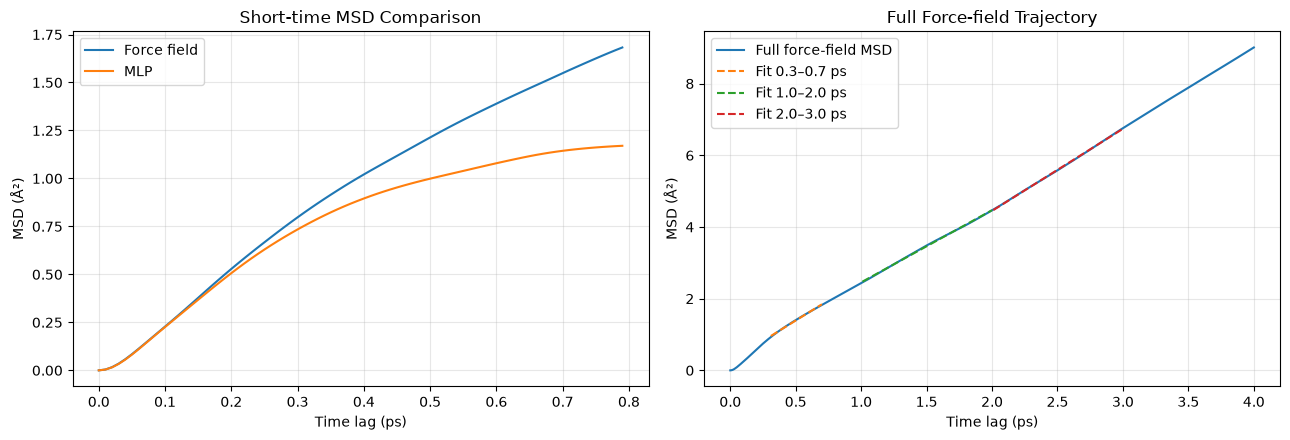

In [8]:

import numpy as np
import matplotlib.pyplot as plt
from ase.io import iread

L = 12.42

def load_full_oxygen_trajectory(filepath, dt_fs, stride_fs=10):
    """Read and unwrap the full oxygen trajectory."""

    stride = max(1, round(stride_fs / dt_fs))
    positions = []
    times = []

    previous = None
    unwrapped = None

    for i, atoms in enumerate(iread(str(filepath), index=":")):
        current = atoms.get_positions()[::3].copy()

        if previous is None:
            unwrapped = current.copy()
        else:
            displacement = current - previous

            # Minimum-image correction for boundary crossings
            displacement -= L * np.rint(displacement / L)
            unwrapped += displacement

        if i % stride == 0:
            positions.append(unwrapped.copy())
            times.append(i * dt_fs / 1000)

        previous = current

    positions = np.asarray(positions)
    times = np.asarray(times)

    # Exclude the first 0.2 ps provisionally
    mask = times >= 0.2

    return positions[mask], times[mask]


# Load the full 10 ps force-field trajectory
dt_ff = np.median(np.diff(ff[:, 1]))

ff_full_positions, ff_full_times = load_full_oxygen_trajectory(
    ff_xyz, dt_ff
)

# Reuse the MSD function from the previous cell
ff_long_lag, ff_long_msd = calculate_msd(
    ff_full_positions,
    ff_full_times,
    max_lag_ps=4.0
)

print(f"Trajectory duration: {ff_full_times[-1]:.2f} ps")
print(f"Number of sampled frames: {len(ff_full_times)}")

# Compare different fitting intervals
fit_windows = [(0.3, 0.7), (1.0, 2.0), (2.0, 3.0)]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Original short-time comparison
axes[0].plot(ff_lag, ff_msd, label="Force field")
axes[0].plot(mlp_lag, mlp_msd, label="MLP")
axes[0].set_title("Short-time MSD Comparison")
axes[0].set_xlabel("Time lag (ps)")
axes[0].set_ylabel("MSD (Å²)")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Longer force-field trajectory
axes[1].plot(
    ff_long_lag, ff_long_msd,
    label="Full force-field MSD"
)

for lower, upper in fit_windows:
    mask = (ff_long_lag >= lower) & (ff_long_lag <= upper)

    x = ff_long_lag[mask]
    y = ff_long_msd[mask]

    slope, intercept = np.polyfit(x, y, 1)

    D = slope / 6 * 1e-8

    # R-squared measures how linear this section is
    fitted = slope * x + intercept
    ss_res = np.sum((y - fitted)**2)
    ss_tot = np.sum((y - np.mean(y))**2)
    r_squared = 1 - ss_res / ss_tot

    print(f"\nFit: {lower:.1f}–{upper:.1f} ps")
    print(f"  D = {D:.3e} m²/s")
    print(f"  R² = {r_squared:.5f}")

    axes[1].plot(
        x, fitted, "--",
        label=f"Fit {lower:.1f}–{upper:.1f} ps"
    )

axes[1].set_title("Full Force-field Trajectory")
axes[1].set_xlabel("Time lag (ps)")
axes[1].set_ylabel("MSD (Å²)")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()
